In [1]:
import numpy as np
import xarray as xr
from scipy.sparse.linalg import svds
from matplotlib import pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from tqdm import tqdm
from ipywidgets import interact
from collections import OrderedDict
from pathlib import Path
from itertools import product
from scipy.linalg import svd
from tslearn.metrics.cycc import normalized_cc

using: <jupyter_rfb._jpg.SimpleJpegEncoder object at 0x7f79e410f110>


Parameters:
* Noise
* Length of recording
* length of single transient
* n_steps
* delay

`DataArray` for each:
* `TdSVD` objects
* normalized `S_0 - S_1` for just `TdSVD`
* normalized `td_S1 - svd_S1`
* normalized cross correlation tdsvd and svd
* max(n_cc) tdsvd and svd

In [2]:
coords = OrderedDict([
    ("noise", 10**np.arange(-1, 1.5, 0.5)), # noise sigma
    ("rlen", np.array([1_000, 5_000, 10_000, 30_000])), # recording length
    ("tlen", np.array([3, 10, 50])), # transient length
    ("n_steps", [3, 10, 25, 50]), # n time steps
    ("delay", [1, 2, 3, 10, 25, 50]), # delay
    # ("evp", [0.005, 0.01, 0.02]) # event probability
])

In [3]:
data_array_names = ["tdsvd", "s_gap_td", "s_gap_svd", "ncc_td", "ncc_svd"]
data_arrays = dict()

for n in data_array_names:
    _data = np.empty(shape=tuple(len(coords[k]) for k in coords.keys()), dtype=object)
    data_arrays[n] = xr.DataArray(
        _data, 
        coords=coords,
    )

In [4]:
a = data_arrays["tdsvd"]
a[a["noise"] == 1, a["rlen"] == 1000, a["tlen"] == 3, a["n_steps"] == 5, a["delay"] == 3]

<xarray.DataArray (noise: 1, rlen: 1, tlen: 1, n_steps: 0, delay: 1)>
array([], shape=(1, 1, 1, 0, 1), dtype=object)
Coordinates:
  * noise    (noise) float64 1.0
  * rlen     (rlen) int64 1000
  * tlen     (tlen) int64 3
  * n_steps  (n_steps) int64 
  * delay    (delay) int64 3

In [5]:
coords["noise"]

array([ 0.1       ,  0.31622777,  1.        ,  3.16227766, 10.        ])

In [6]:
toy_datasets = dict()
toy_datasets_clean = dict()
for noise in coords["noise"]:
    toy_shape = (2, 30_000)
    p1 = 0.01
    pixels = np.random.choice(a=[0, 1], size=toy_shape, p=[1-p1, p1])
    pixels[1:] = pixels[0]
    
    pixels[pixels == 2] = 1
    
    for i in range(pixels.shape[0]):
        for j in range(10):
            pixels[i] += np.roll(pixels[i], shift=1)
    
    pixels[pixels > 1] = 1
    pixels = pixels.astype(float)
    
    pixels_clean = pixels.copy()
    
    for i in range(pixels.shape[0]):
        pixels[i] += np.random.normal(0, noise, size=toy_shape[1])

    toy_datasets[noise] = pixels
    toy_datasets_clean[noise] = pixels_clean

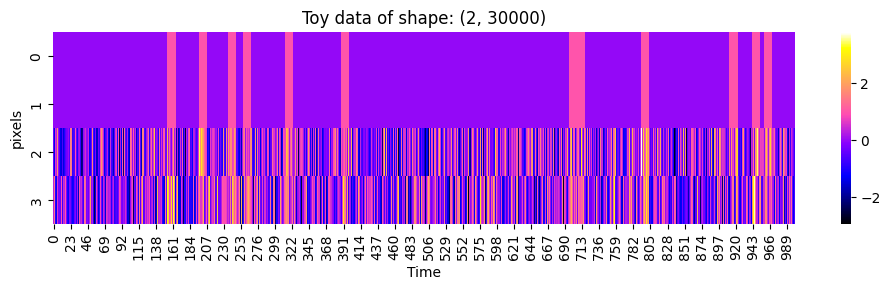

In [7]:
fig = plt.figure(figsize=(10, 3))
noise_index = 2
sns.heatmap(
    np.vstack(
        [
            toy_datasets_clean[coords["noise"][noise_index]], 
            toy_datasets[coords["noise"][noise_index]]
        ]
    )[:, :1000], 
    cmap="gnuplot2"
)
plt.title(f"Toy data of shape: {toy_shape}")
plt.xlabel("Time")
plt.ylabel("pixels"), pixels
plt.tight_layout()
plt.show()

In [8]:
class TdSVD:
    @staticmethod
    def create_embedding(data: np.ndarray, n_time_steps: int, delay: int, filename: str):
        if Path(f"embeddings/{filename}").exists():
            shape = filename.split("_shape_")[1].split("-")
            return np.memmap(filename, dtype=np.float32, mode="r", shape=shape)

        n_timepoints = data.shape[1]
        n_pixels = data.shape[0]
        
        A = np.zeros((n_pixels * n_time_steps, n_timepoints - (n_time_steps * delay)), dtype=np.float32)
        
        for pixel_ix in range(n_pixels):
            for step in range(n_time_steps):
                A[(n_time_steps * pixel_ix) + step] = np.roll(data[pixel_ix], shift=-delay * step)[:-n_time_steps * delay]

        fp = np.memmap(f"./embeddings/{filename}_shape_{A.shape[0]}-{A.shape[1]}", dtype=np.float32, mode="w+", shape=A.shape)
        fp[:] = A[:]
        fp.flush()

        del A

        return fp
        
    def __init__(
        self,
        data: np.ndarray,
        filename_embedding: str,
        n_time_steps: int,
        delay: int,
    ):
        self.n_time_steps = n_time_steps
        
        n_timepoints = data.shape[1]
        self.n_pixels = data.shape[0]

        self.A = self.create_embedding(data, n_time_steps, delay, filename_embedding)

        self.k, self.U, self.S, self.V = None, None, None, None
    
    def fit(self, k=6, **kwargs):
        self.k = k
        U, S, V = svds(self.A, k=self.k, **kwargs)
        self.U = U[:, ::-1]
        self.S = S[::-1]
        self.V = V[::-1, :]

    def get_spatial(self):
        return self.U.reshape(self.n_pixels, self.n_time_steps, self.k)

In [9]:
def product_dict(kwargs):
    keys = kwargs.keys()
    for instance in product(*kwargs.values()):
        yield OrderedDict(zip(keys, instance))

In [10]:
len(list(product_dict(coords)))

1440

In [11]:
for i, params in enumerate(list(product_dict(coords))):
    print(params)
    if i > 20:
        break

OrderedDict([('noise', 0.1), ('rlen', 1000), ('tlen', 3), ('n_steps', 3), ('delay', 1)])
OrderedDict([('noise', 0.1), ('rlen', 1000), ('tlen', 3), ('n_steps', 3), ('delay', 2)])
OrderedDict([('noise', 0.1), ('rlen', 1000), ('tlen', 3), ('n_steps', 3), ('delay', 3)])
OrderedDict([('noise', 0.1), ('rlen', 1000), ('tlen', 3), ('n_steps', 3), ('delay', 10)])
OrderedDict([('noise', 0.1), ('rlen', 1000), ('tlen', 3), ('n_steps', 3), ('delay', 25)])
OrderedDict([('noise', 0.1), ('rlen', 1000), ('tlen', 3), ('n_steps', 3), ('delay', 50)])
OrderedDict([('noise', 0.1), ('rlen', 1000), ('tlen', 3), ('n_steps', 10), ('delay', 1)])
OrderedDict([('noise', 0.1), ('rlen', 1000), ('tlen', 3), ('n_steps', 10), ('delay', 2)])
OrderedDict([('noise', 0.1), ('rlen', 1000), ('tlen', 3), ('n_steps', 10), ('delay', 3)])
OrderedDict([('noise', 0.1), ('rlen', 1000), ('tlen', 3), ('n_steps', 10), ('delay', 10)])
OrderedDict([('noise', 0.1), ('rlen', 1000), ('tlen', 3), ('n_steps', 10), ('delay', 25)])
OrderedDict

In [ ]:
for params in tqdm(list(product_dict(coords))):
    data = toy_datasets[params["noise"]][:, :params["rlen"]]
    data_clean = toy_datasets_clean[params["noise"]][:, :params["rlen"]]
    fname = "_".join(f"{k}-{v}" for k, v in params.items())

    tdsvd = TdSVD(
        data=data,
        filename_embedding=fname,
        n_time_steps=params["n_steps"],
        delay=params["delay"]
    )

    tdsvd.fit(k=2)

    data_arrays["tdsvd"] = tdsvd
    
    snorm_td = tdsvd.S / tdsvd.S.max()
    data_arrays["s_gap_td"] = snorm_td[0] - snorm_td[1]

    if abs(min(tdsvd.V[0])) > max(tdsvd.V[0]):
        sign = -1
    else:
        sign = 1
    
    ncc_td = normalized_cc(data_clean[0, :tdsvd.V.shape[1]].reshape(-1, 1), sign * tdsvd.V[0].reshape(-1, 1))
    data_arrays["ncc_td"] = ncc_td

    u, s, v = svd(pixels.astype(float))
    snorm = s / s.max()
    data_arrays["s_gap_svd"] = snorm[0] - snorm[1]

    if abs(min(v[0])) > max(v[0]):
        sign = -1
    else:
        sign = 1
    
    ncc_svd = normalized_cc(data_clean[0].reshape(-1, 1), sign * v[0].reshape(-1, 1))
    data_arrays["ncc_svd"] = ncc_svd

  0%|                                                                                                              | 0/1440 [00:00<?, ?it/s]

In [16]:
min(np.array([1, 2, 5, -1]))

-1

In [52]:
data_array_names

['tdsvd', 's_gap_td', 's_gap_svd', 'ncc_td', 'ncc_svd']

In [28]:
"_".join(f"{k}-{v}" for k, v in zip(coords.keys(), params))

'noise-0.1_rlen-1000_tlen-3_n_steps-3_delay-1'

In [24]:
coords.values()

odict_values([array([ 0.1       ,  0.31622777,  1.        ,  3.16227766, 10.        ]), array([ 1000,  5000, 10000, 15000, 30000]), array([ 3,  5,  7, 10, 15, 20, 30, 50]), array([ 3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
       20, 21, 22, 23, 24]), array([1, 2, 3, 4, 5, 6, 7, 8, 9])])

In [197]:
noise = 1
rlen = 5_000
tlen = 3
n_steps = 3
delay = 1



tdsvd = TdSVD(
    data=pixels, 
    filename_embedding=f"noise-{noise}-rlen-{rlen}-tlen-{tlen}-n_steps-{n_steps}-delay-{delay}",
    n_time_steps=n_steps,
    delay=delay
)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00, 2077.93it/s]


In [198]:
tdsvd.fit(k=3)

In [6]:
%matplotlib ipympl

In [7]:
import seaborn as sns

In [8]:
tdsvd = None

In [9]:
@interact(n_time_steps=(1, 25), delay=(1, 50), k=(2, 10))
def plot_everything(n_time_steps: int = 5, delay: int = 1, k: int = 4):
    fig = plt.figure(figsize=(15, 10))
    grid = plt.GridSpec(10, 10)
    
    toy_plot = fig.add_subplot(grid[0, :])
    sns.heatmap(np.vstack([pixels_clean]), cmap="gnuplot2", ax=toy_plot)
    toy_plot.set_title(f"Toy data of shape: {toy_shape}")
    toy_plot.set_xlabel("Time")
    toy_plot.set_ylabel("pixels")

    toy_plot_noise = fig.add_subplot(grid[1:2, :])
    sns.heatmap(np.vstack([pixels]), cmap="gnuplot2", ax=toy_plot_noise)
    toy_plot_noise.set_title(f"Toy data  + noise: {toy_shape}")
    toy_plot_noise.set_xlabel("Time")
    toy_plot_noise.set_ylabel("pixels")

    global tdsvd
    tdsvd = TdSVD(pixels, n_time_steps=n_time_steps, delay=delay)
    tdsvd.fit(k=k)
    
    plot_embed = fig.add_subplot(grid[2:7, :])
    sns.heatmap(tdsvd.A[:, :200], cmap="gnuplot2", ax=plot_embed)
    plot_embed.set_title(f"Time embedding, shape: {tdsvd.A.shape}, n_steps: {tdsvd.n_time_steps}")
    plot_embed.set_xlabel("Time")
    plot_embed.set_ylabel("pixels over steps")
    
    plot_svals = fig.add_subplot(grid[8:, :3])
    plot_svals.scatter(np.arange(tdsvd.S.size), tdsvd.S / tdsvd.S.max())
    plot_svals.set_yscale("log")
    for x, y in zip(np.arange(tdsvd.S.size), tdsvd.S):
        plot_svals.annotate(f"{y:.2e}", (x + 0.05, y))
    
    plot_svals.set_title(f"Singular values: {np.array2string(tdsvd.S / tdsvd.S.max(), precision=3)}")
    
    plot_u = fig.add_subplot(grid[8:, 3:6])
    img_u = sns.heatmap(tdsvd.U, ax=plot_u, cmap="seismic")
    # fig.colorbar(img_u)
    plot_u.set_title(f"Left singular vectors, shape: {tdsvd.U.shape}")
    
    plot_v = fig.add_subplot(grid[7:, 6:])
    img_v = sns.heatmap(np.vstack([pixels_clean[0, :tdsvd.V.shape[1]] / 10, tdsvd.V]), cmap="seismic", ax=plot_v)
    # fig.colorbar(img_v)
    plot_v.set_title(f"Right singular vectors, shape: {tdsvd.V.shape}")
    
    fig.tight_layout()
    plt.show()

interactive(children=(IntSlider(value=5, description='n_time_steps', max=25, min=1), IntSlider(value=1, descri…

In [199]:
from scipy.linalg import svd

In [55]:
u, s, v = svd(pixels.astype(float))

In [57]:
snorm = s / s.max()
snorm

array([1.        , 0.99327969])

In [58]:
snorm[0] - snorm[1]

0.006720306338879545

In [202]:
tdsvd.S / tdsvd.S.max()

array([1.       , 0.5982902, 0.5777136], dtype=float32)

In [156]:
%matplotlib ipympl

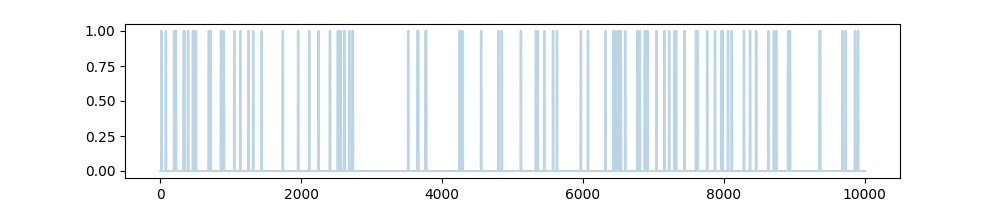

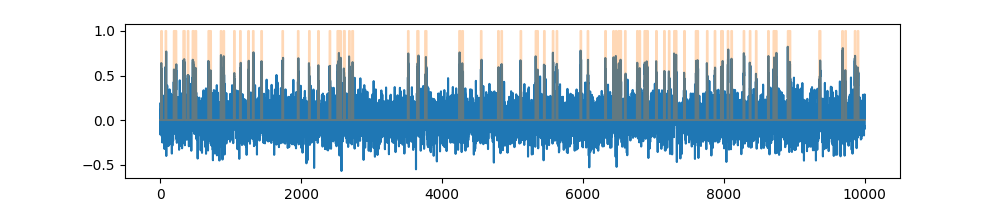

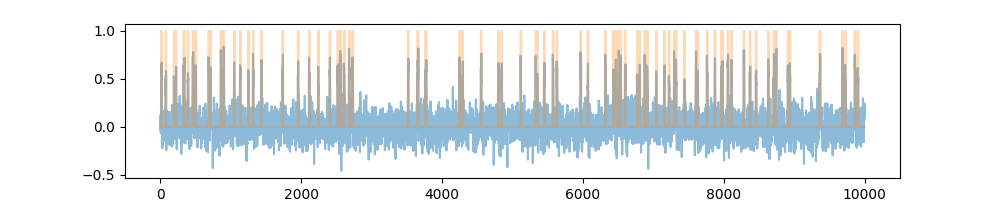

In [204]:
fig = plt.figure(figsize=(10, 2))
plt.plot(pixels_clean.mean(axis=0), alpha=0.3)
plt.show()

# fig = plt.figure(figsize=(10, 2))
# plt.plot(pixels.mean(axis=0))
# # plt.show()

fig = plt.figure(figsize=(10, 2))
plt.plot(-v[0] * 20)
plt.plot(pixels_clean.mean(axis=0), alpha=0.3)
plt.show()

fig = plt.figure(figsize=(10, 2))
plt.plot(-tdsvd.V[0]*20, alpha=0.5)
plt.plot(pixels_clean.mean(axis=0), alpha=0.3)
plt.show()



In [205]:
from tslearn.metrics.cycc import normalized_cc

In [164]:
pixels_clean.shape

(2, 10000)

In [165]:
tdsvd.V.shape

(3, 9997)

In [173]:
tdsvd.V[0].shape

(9997,)

In [174]:
pixels_clean[0, :tdsvd.V.shape[1]].shape

(9997,)

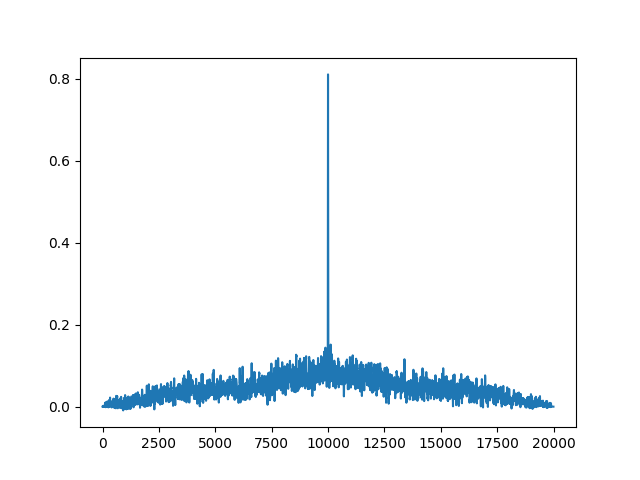

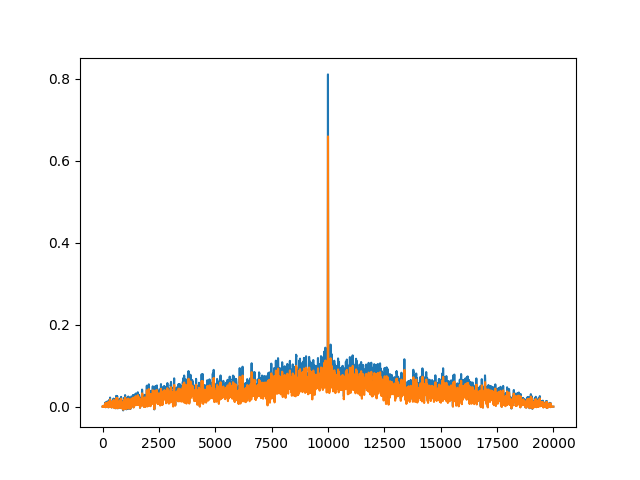

In [207]:
fig = plt.figure()

plt.plot(normalized_cc(pixels_clean[0, :tdsvd.V.shape[1]].reshape(-1, 1), -tdsvd.V[0].reshape(-1, 1)))
plt.show()

plt.plot(normalized_cc(pixels_clean[0].reshape(-1, 1), -v[0].reshape(-1, 1)))
plt.show()

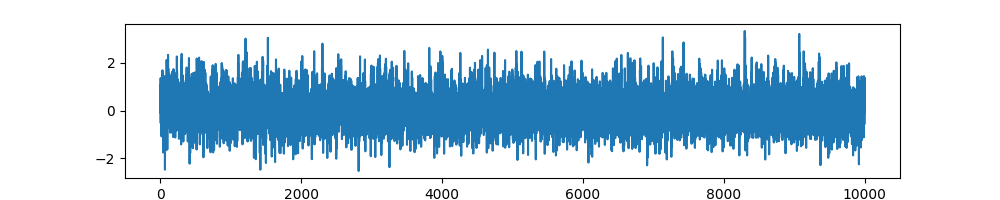

In [15]:
fig = plt.figure(figsize=(10, 2))
plt.plot(pixels.mean(axis=0))
plt.show()

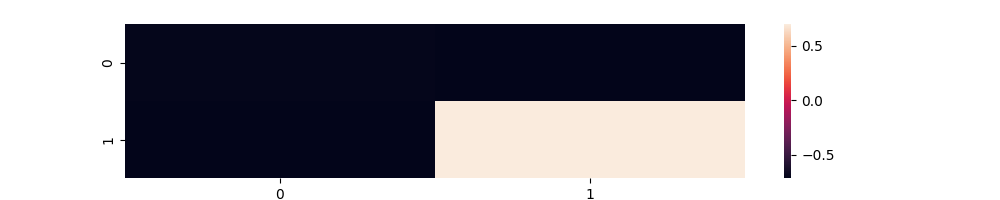

In [15]:
fig = plt.figure(figsize=(10, 2))
sns.heatmap(u)
plt.show()